# Deep Neural Network:

<a name='1'></a>
## 1 - Packages

In [18]:
# Package imports
from time import perf_counter
import os      
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import MinMaxScaler
from dnn_app_utils_v3 import *

np.random.seed(10)

<a name='2'></a>
## 2 - Load the Dataset and Normalization

In [2]:
# Loading the data
weather_2021 = pd.read_csv("Data/ninja_weather_2021.csv", comment="#")
weather_2022 = pd.read_csv("Data/ninja_weather_2022.csv", comment="#")
weather_2023 = pd.read_csv("Data/ninja_weather_2023.csv", comment="#")
weather_2024 = pd.read_csv("Data/ninja_weather_2024.csv", comment="#")
weather_2025 = pd.read_csv("Data/ninja_weather_2025.csv", comment="#")

pv_2021 = pd.read_csv("Data/ninja_pv_2021.csv", comment="#")
pv_2022 = pd.read_csv("Data/ninja_pv_2022.csv", comment="#")
pv_2023 = pd.read_csv("Data/ninja_pv_2023.csv", comment="#")
pv_2024 = pd.read_csv("Data/ninja_pv_2024.csv", comment="#")
pv_2025 = pd.read_csv("Data/ninja_pv_2025.csv", comment="#")

In [ ]:
# Merging the weather and pv data
weather = pd.concat([weather_2021, weather_2022, weather_2023, weather_2024, weather_2025], ignore_index=True)
pv = pd.concat([pv_2021, pv_2022, pv_2023, pv_2024, pv_2025], ignore_index=True)

data = pd.merge(weather, pv, on="time")

data["time"] = pd.to_datetime(data["time"])    # timestamps as datetime
data = data.set_index("time")                  # set time as the index
                                                
 
time = data.index                              # keep the timestamps
input_data = data.values                       # .values converts a pandas dataframe to a numpy array

In [4]:
split = int(0.8 * input_data.shape[0])   # 80/20 split
 
train_set_x_orig = input_data[:split, 0:8]
test_set_x_orig = input_data[split:, 0:8]
train_set_y_orig = input_data[:split, -1:]
test_set_y_orig = input_data[split:, -1:]

## 5 - L-layer Neural Network


In [5]:
# evaluation metrics (L9), all in kW: the same function is used for the CV (train and validation folds) and for the final model (train and test set)
# MAPE is not used because the PV output is 0 during the night (division by zero)
capacity = 1000    # installed capacity in kW (Renewables.ninja setting), used for the normalized errors

def evaluate(y_true, y_pred):
    error = y_pred - y_true
    mae = np.mean(np.abs(error))
    mse = np.mean(error ** 2)
    rmse = np.sqrt(mse)
    mbe = np.mean(error)                     # bias: > 0 means the model overestimates on average
    r2 = 1 - np.sum(error ** 2) / np.sum((y_true - np.mean(y_true)) ** 2)
    return {"MAE": mae,
            "MSE": mse,
            "RMSE": rmse,
            "R2": r2}

metrics = list(evaluate(np.array([0.0, 1.0]), np.array([0.0, 1.0])).keys())    # names of all metrics

In [6]:
def L_layer_model(X, Y, layers_dims, learning_rate, num_iterations, print_cost=False):
 
    costs = []                                          
 
    # Parameters initialization
    parameters = initialize_parameters_deep(layers_dims)
 
    # Loop (gradient descent)
    for i in range(0, num_iterations):
 
        # Forward propagation:
        AL, caches = L_model_forward(X, parameters)
 
        # Compute cost
        cost = compute_cost(AL, Y)
 
        # Backward propagation
        grads = L_model_backward(AL, Y, caches)
 
        # Update parameters
        parameters = update_parameters(parameters, grads, learning_rate)
 
        # Print the cost every 100 iterations
        if i % 100 == 0:
            costs.append(cost)
            if print_cost:
                print("Cost after iteration %i: %f" % (i, cost))
 
    return parameters, costs

In [7]:
def model(train_set_x_normalized, train_set_y_normalized, test_set_x_normalized, test_set_y_normalized, layers_dims, num_iterations=3000, learning_rate=0.0075, print_cost=False):
 
    # tic-toc: time needed for the optimization (training)
    tic = perf_counter()
    parameters, costs = L_layer_model(train_set_x_normalized, train_set_y_normalized, layers_dims, learning_rate, num_iterations, print_cost)
    toc = perf_counter()
 
    Y_prediction_test, caches = L_model_forward(test_set_x_normalized, parameters)
    Y_prediction_train, caches = L_model_forward(train_set_x_normalized, parameters)
 
    # Print train/test Errors
    if print_cost:
        #print("train accuracy: {} %".format(100 - np.mean(np.abs(Y_prediction_train - train_set_y_normalized)) * 100))
        #print("test accuracy: {} %".format(100 - np.mean(np.abs(Y_prediction_test - test_set_y_normalized)) * 100))
        #print("training time: {:.2f} s".format(toc - tic))
        print(evaluate(test_set_y_normalized, Y_prediction_test))

 
    d = {"costs": costs,
         "Y_prediction_test": Y_prediction_test,
         "Y_prediction_train": Y_prediction_train,
         "parameters": parameters,
         "layers_dims": layers_dims,
         "learning_rate": learning_rate,
         "num_iterations": num_iterations,
         "train_time": toc - tic}
    return d

### Evaluation based upon L9

All errors are computed in kW (after reversing the normalization) and the same function is used for the cross-validation (train and validation folds) and for the final model (train and test set), so that all numbers can be compared directly.

| Metric | Formula | Meaning |
|---|---|---|
| MAE | $\frac{1}{m}\sum \lvert \hat{y}-y \rvert$ | mean absolute error in kW |
| MSE | $\frac{1}{m}\sum (\hat{y}-y)^2$ | mean squared error in kW² |
| RMSE | $\sqrt{MSE}$ | penalizes large errors more than MAE, in kW |
| R² | $1 - \frac{\sum (\hat{y}-y)^2}{\sum (y-\bar{y})^2}$ | share of the variance that the model explains |

MAPE is not used because the PV output is 0 during the night (division by zero).

### Documentation of the results

All results (every CV setting, the final test results and the feature importance) are written to `results/model_comparison.xlsx`. The file is shared between the notebooks: every notebook only replaces its own rows (column `model`), so the logistic regression, the shallow NN and the deep NN end up in the same tables and can be compared directly.

| Sheet | Content |
|---|---|
| `cv` | one row per hyperparameter setting: mean train and validation errors over the folds, std of the validation errors, training time per fold and per iteration |
| `test` | one row per model: best hyperparameters, train and test periods, mean CV validation errors, train and test errors of the final model, training time (total and per iteration), prediction time and grid search time |
| `feature_importance` | correlation, sensitivity (and weights for the logistic regression) and permutation importance per input feature |

In [8]:
# Shared results file (same function as in 01_Logistic_Regression)
model_name = "Deep NN"
results_file = "results/model_comparison.xlsx"

def save_results(tables, model_name, file=results_file):
    # tables: {sheet name: DataFrame}. Old rows of the same model are replaced, rows of other models are kept
    os.makedirs(os.path.dirname(file), exist_ok=True)
    sheets = pd.read_excel(file, sheet_name=None) if os.path.exists(file) else {}

    for sheet, table in tables.items():
        old = sheets.get(sheet, pd.DataFrame())
        if "model" in old.columns:
            old = old[old["model"] != model_name]
        sheets[sheet] = pd.concat([old, table], ignore_index=True)

    with pd.ExcelWriter(file) as writer:
        for sheet, table in sheets.items():
            table.to_excel(writer, sheet_name=sheet, index=False)

In [ ]:
# Cross validation: rolling window with a gap (only the training set)
n_splits = 5
gap = 24                 # 24 h gap between training and validation
train_share = 0.5        # share of the training set that one fold uses for training

n_train = len(train_set_x_orig)
val_size = int((n_train - gap) * (1 - train_share) / n_splits)   # validation hours per fold
train_window = n_train - n_splits * val_size - gap               # training hours per fold

tscv = TimeSeriesSplit(n_splits=n_splits, max_train_size=train_window, gap=gap, test_size=val_size)

def cross_validate(hidden_layers, num_iterations, learning_rate):
 
    train_scores = []
    val_scores = []
    train_times = []
 
    for fold, (train_idx, val_idx) in enumerate(tscv.split(train_set_x_orig)):
        x_train = train_set_x_orig[train_idx]
        x_val = train_set_x_orig[val_idx]
        y_train = train_set_y_orig[train_idx]
        y_val = train_set_y_orig[val_idx]
 
        # normalization: fit only on the training fold, then apply to the validation fold
        scaler_x = MinMaxScaler(feature_range=(0,1))
        scaler_y = MinMaxScaler(feature_range=(0,1))
        x_train_normalized = scaler_x.fit_transform(x_train)
        x_val_normalized = scaler_x.transform(x_val)
        y_train_normalized = scaler_y.fit_transform(y_train)
        y_val_normalized = scaler_y.transform(y_val)
 
        # transpose: features in the rows, samples in the columns
        x_train_normalized = x_train_normalized.T
        x_val_normalized = x_val_normalized.T
        y_train_normalized = y_train_normalized.T
        y_val_normalized = y_val_normalized.T
 
        # layer sizes: input layer, hidden layers, output layer
        layers_dims = [x_train_normalized.shape[0]] + hidden_layers + [1]
 
        # train on the training fold, predict the validation fold
        fold_model = model(x_train_normalized, y_train_normalized, x_val_normalized, y_val_normalized, layers_dims, num_iterations, learning_rate)
 
        # reverse normalization (back to kW) and evaluation on both the training and the validation fold
        y_train_pred_kw = scaler_y.inverse_transform(fold_model["Y_prediction_train"].T)
        y_val_pred_kw = scaler_y.inverse_transform(fold_model["Y_prediction_test"].T)
        train_scores.append(evaluate(y_train, y_train_pred_kw))
        val_scores.append(evaluate(y_val, y_val_pred_kw))
        train_times.append(fold_model["train_time"])
 
    return pd.DataFrame(train_scores), pd.DataFrame(val_scores), train_times

## CV and results

In [10]:
# ---------- hyperparameter selection with the cross-validation ----------
hidden_layers_list = [[6, 4], [8, 4], [16, 8]]     # sizes of the hidden layers 2 deep
learning_rates = [0.85, 2.0]
iterations_list = [1000, 5000, 10000]
 
cv_results = []
best_rmse = np.inf
tic_cv = perf_counter()
 
for hidden_layers in hidden_layers_list:
    for learning_rate in learning_rates:
        for num_iterations in iterations_list:
            train_scores, val_scores, train_times = cross_validate(hidden_layers, num_iterations, learning_rate)

            # one row per setting: mean over the folds (and std of the validation errors)
            row = {"model": model_name, "hidden_layers": str(hidden_layers), "learning_rate": learning_rate, "num_iterations": num_iterations}
            row.update(train_scores.mean().add_prefix("train_").to_dict())
            row.update(val_scores.mean().add_prefix("val_").to_dict())
            row.update(val_scores.std(ddof=0).add_prefix("val_std_").to_dict())
            row["train_time_per_fold_s"] = np.mean(train_times)
            row["time_per_iteration_ms"] = np.mean(train_times) / num_iterations * 1000
            cv_results.append(row)

            print("hidden layers:", hidden_layers, "| learning rate:", learning_rate, "| iterations:", num_iterations,
                  "| mean val MAE = %.2f, RMSE = %.2f, R2 = %.4f" % (row["val_MAE"], row["val_RMSE"], row["val_R2"]),
                  "| training time per fold = %.2f s" % row["train_time_per_fold_s"])
 
            if row["val_RMSE"] < best_rmse:         # the mean validation RMSE decides
                best_rmse = row["val_RMSE"]
                best_hidden_layers = hidden_layers
                best_learning_rate = learning_rate
                best_num_iterations = num_iterations
                best = row
                best_val_scores = val_scores

toc_cv = perf_counter()
cv_results = pd.DataFrame(cv_results)
 
print("best setting: hidden layers =", best_hidden_layers, ", learning rate =", best_learning_rate, ", iterations =", best_num_iterations, ", mean RMSE =", best_rmse)
print("total time of the grid search: %.1f s" % (toc_cv - tic_cv))
 
# periods and validation errors per fold for the best setting
for fold, (train_idx, val_idx) in enumerate(tscv.split(train_set_x_orig)):
    print("fold", fold + 1, "| training:", time[train_idx[0]], "to", time[train_idx[-1]], "| validation:", time[val_idx[0]], "to", time[val_idx[-1]])

best_val_scores.index = ["fold %d" % (k + 1) for k in range(n_splits)]
print("validation errors per fold:")
print(best_val_scores)

cv_results

hidden layers: [6, 4] | learning rate: 0.85 | iterations: 1000 | mean val MAE = 19.95, RMSE = 38.57, R2 = 0.9433 | training time per fold = 11.42 s
hidden layers: [6, 4] | learning rate: 0.85 | iterations: 5000 | mean val MAE = 16.73, RMSE = 34.14, R2 = 0.9586 | training time per fold = 36.67 s
hidden layers: [6, 4] | learning rate: 0.85 | iterations: 10000 | mean val MAE = 16.01, RMSE = 33.24, R2 = 0.9620 | training time per fold = 65.04 s
hidden layers: [6, 4] | learning rate: 2.0 | iterations: 1000 | mean val MAE = 23.08, RMSE = 42.55, R2 = 0.9402 | training time per fold = 6.68 s
hidden layers: [6, 4] | learning rate: 2.0 | iterations: 5000 | mean val MAE = 19.58, RMSE = 37.79, R2 = 0.9554 | training time per fold = 35.09 s
hidden layers: [6, 4] | learning rate: 2.0 | iterations: 10000 | mean val MAE = 18.88, RMSE = 36.78, R2 = 0.9585 | training time per fold = 75.11 s
hidden layers: [8, 4] | learning rate: 0.85 | iterations: 1000 | mean val MAE = 21.02, RMSE = 41.25, R2 = 0.9332 |

,model,hidden_layers,learning_rate,num_iterations,train_MAE,train_MSE,train_RMSE,train_R2,val_MAE,val_MSE,val_RMSE,val_R2,val_std_MAE,val_std_MSE,val_std_RMSE,val_std_R2,train_time_per_fold_s,time_per_iteration_ms
0,Deep NN,"[6, 4]",0.85,1000,19.011421,1384.345526,37.200284,0.964676,19.954594,1518.287240,38.573793,0.943286,4.600590,404.843273,5.509061,0.030123,11.421369,11.421369
1,Deep NN,"[6, 4]",0.85,5000,17.538473,1333.497637,36.507149,0.965978,16.729074,1221.414247,34.135572,0.958555,5.155295,495.944766,7.495128,0.016300,36.669945,7.333989
2,Deep NN,"[6, 4]",0.85,10000,16.686682,1260.302188,35.485455,0.967868,16.005094,1174.189513,33.244566,0.961982,5.528159,530.936810,8.305922,0.013501,65.037579,6.503758
3,Deep NN,"[6, 4]",2.00,1000,23.568316,2007.734216,44.791475,0.948805,23.083219,1963.858511,42.547576,0.940172,10.720430,1086.699876,12.392026,0.019652,6.675420,6.675420
4,Deep NN,"[6, 4]",2.00,5000,18.952529,1499.674552,38.651869,0.961787,19.581315,1567.943264,37.792730,0.955448,9.179897,852.946978,11.817481,0.009481,35.094288,7.018858
5,Deep NN,"[6, 4]",2.00,10000,18.304885,1443.623714,37.906377,0.963248,18.881042,1512.282959,36.783247,0.958549,9.117320,869.861772,12.620447,0.010867,75.105987,7.510599
6,Deep NN,"[8, 4]",0.85,1000,20.002160,1610.980913,40.131524,0.958889,21.021468,1773.125582,41.250348,0.933212,5.459054,682.457082,8.457799,0.036590,8.258138,8.258138
7,Deep NN,"[8, 4]",0.85,5000,16.481018,1246.280944,35.297989,0.968195,17.388161,1413.347618,36.707334,0.948859,4.964723,584.444082,8.119065,0.026117,40.740274,8.148055
8,Deep NN,"[8, 4]",0.85,10000,15.197580,1115.987207,33.400201,0.971525,16.151568,1303.423791,35.081458,0.954056,4.923511,588.279767,8.527313,0.023335,71.844040,7.184404
9,Deep NN,"[8, 4]",2.00,1000,19.665558,1648.328932,40.583595,0.957968,18.993048,1557.764885,38.463055,0.941807,6.853037,714.090228,8.852020,0.036046,2.495250,2.495250


In [11]:
# Final model: whole training set, evaluation on the test set
scaler_x = MinMaxScaler(feature_range=(0,1))
scaler_y = MinMaxScaler(feature_range=(0,1))
train_set_x_normalized = scaler_x.fit_transform(train_set_x_orig)
test_set_x_normalized = scaler_x.transform(test_set_x_orig)
train_set_y_normalized = scaler_y.fit_transform(train_set_y_orig)
test_set_y_normalized = scaler_y.transform(test_set_y_orig)
 
train_set_x_normalized = train_set_x_normalized.T     
test_set_x_normalized = test_set_x_normalized.T
train_set_y_normalized = train_set_y_normalized.T
test_set_y_normalized = test_set_y_normalized.T
 
layers_dims = [train_set_x_normalized.shape[0]] + best_hidden_layers + [1]
 
deep_nn_model = model(train_set_x_normalized, train_set_y_normalized, test_set_x_normalized, test_set_y_normalized, layers_dims, best_num_iterations, best_learning_rate, print_cost=True)

Cost after iteration 0: 0.692337
Cost after iteration 100: 0.218397
Cost after iteration 200: 0.211081
Cost after iteration 300: 0.207545
Cost after iteration 400: 0.206062
Cost after iteration 500: 0.205137
Cost after iteration 600: 0.204442
Cost after iteration 700: 0.203949
Cost after iteration 800: 0.203492
Cost after iteration 900: 0.203035
Cost after iteration 1000: 0.202710
Cost after iteration 1100: 0.202412
Cost after iteration 1200: 0.202197
Cost after iteration 1300: 0.202031
Cost after iteration 1400: 0.201856
Cost after iteration 1500: 0.201662
Cost after iteration 1600: 0.201561
Cost after iteration 1700: 0.201451
Cost after iteration 1800: 0.201422
Cost after iteration 1900: 0.201326
Cost after iteration 2000: 0.201223
Cost after iteration 2100: 0.201157
Cost after iteration 2200: 0.201042
Cost after iteration 2300: 0.200983
Cost after iteration 2400: 0.200935
Cost after iteration 2500: 0.200842
Cost after iteration 2600: 0.200790
Cost after iteration 2700: 0.200733
Cost

,CV train (mean),CV validation (mean),CV validation (std),final model train,test
MAE,14.152468,14.175747,4.841415,14.606841,14.611887
MSE,1014.023589,1034.694726,430.357860,1043.983104,1067.086783
RMSE,31.835168,31.233325,7.692473,32.310727,32.666294
R2,0.974134,0.967147,0.010692,0.972885,0.972038


training time final model (s)                        169.758673
time per iteration (ms)                               16.975867
prediction time test set (s)                           0.007897
mean training time per CV fold, best setting (s)      28.105427
total grid search time (s)                          3839.678834


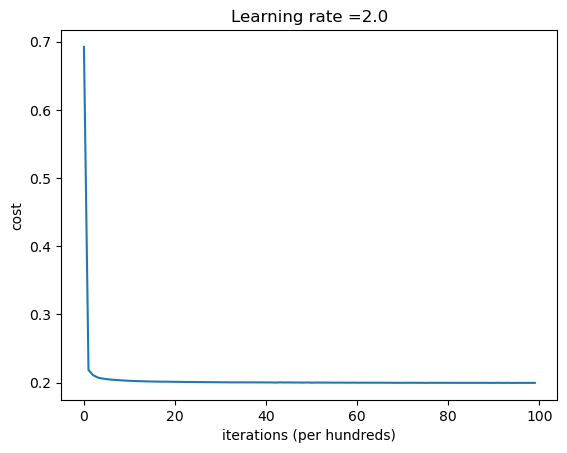

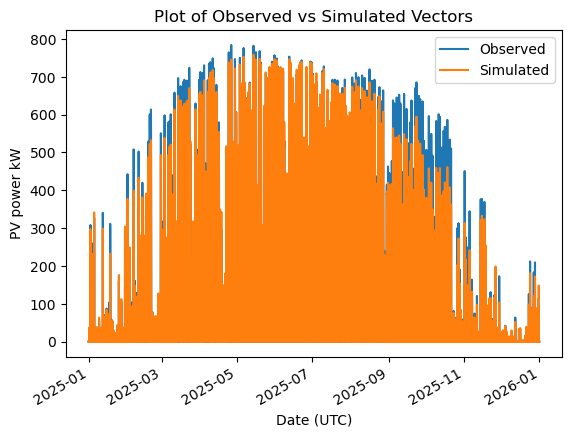

In [12]:
# Reverse normalization
Y_prediction_train_real_scale = scaler_y.inverse_transform(deep_nn_model["Y_prediction_train"].T)
Y_prediction_test_real_scale = scaler_y.inverse_transform(deep_nn_model["Y_prediction_test"].T)

# Tic toc: time needed to predict the whole test set
tic = perf_counter()
L_model_forward(test_set_x_normalized, deep_nn_model["parameters"])
toc = perf_counter()
predict_time = toc - tic

train_scores = evaluate(train_set_y_orig, Y_prediction_train_real_scale)
test_scores = evaluate(test_set_y_orig, Y_prediction_test_real_scale)

# CV and test side by side (same metrics, all in kW)
comparison = pd.DataFrame({"CV train (mean)": [best["train_" + m] for m in metrics],
                           "CV validation (mean)": [best["val_" + m] for m in metrics],
                           "CV validation (std)": [best["val_std_" + m] for m in metrics],
                           "final model train": [train_scores[m] for m in metrics],
                           "test": [test_scores[m] for m in metrics]},
                          index=metrics)
display(comparison)

# Computation times (tic toc)
times = pd.Series({"training time final model (s)": deep_nn_model["train_time"],
                   "time per iteration (ms)": deep_nn_model["train_time"] / best_num_iterations * 1000,
                   "prediction time test set (s)": predict_time,
                   "mean training time per CV fold, best setting (s)": best["train_time_per_fold_s"],
                   "total grid search time (s)": toc_cv - tic_cv})
print(times.to_string())
 
# Plot learning curve (with costs)
costs = np.squeeze(deep_nn_model['costs'])
plt.plot(costs)
plt.ylabel('cost')
plt.xlabel('iterations (per hundreds)')
plt.title("Learning rate =" + str(deep_nn_model["learning_rate"]))
plt.show()
 
# Results analysis
x = time[split:]                               # datetime index of the test period
y1 = test_set_y_orig
y2 = Y_prediction_test_real_scale
 
plt.plot(x, y1, label='Observed')
plt.plot(x, y2, label='Simulated')
plt.title('Plot of Observed vs Simulated Vectors')
plt.xlabel('Date (UTC)')
plt.ylabel('PV power kW')
plt.ylim()
plt.legend()
plt.gcf().autofmt_xdate()                    # tilt the date labels
plt.show()

# one row for the results file (same columns as in the other notebooks)
test_results = {"model": model_name, "hidden_layers": str(best_hidden_layers), "learning_rate": best_learning_rate, "num_iterations": best_num_iterations}
test_results.update({"cv_val_" + m: best["val_" + m] for m in metrics})
test_results.update({"train_" + m: train_scores[m] for m in metrics})
test_results.update({"test_" + m: test_scores[m] for m in metrics})
test_results.update({"train_time_s": deep_nn_model["train_time"],
                     "predict_time_test_s": predict_time,
                     "grid_search_time_s": toc_cv - tic_cv})
test_results = pd.DataFrame([test_results])

## Feature Importance

Three ways to see which inputs matter for the PV output:

1. **Correlation** (Pearson, on the training set): linear relation between each input and the output, independent of the model. Fast, but it ignores interactions and non-linear effects.
2. **Sensitivity** (by hand from the equations): the derivative of the prediction with respect to each input, with the chain rule backwards through the layers (ReLU in the hidden layers, sigmoid at the output):
$$\frac{\partial \hat{y}}{\partial x} = W^{[1]T} \, \mathrm{relu}'(z^{[1]}) * \left( \dots \, W^{[L-1]T} \, \mathrm{relu}'(z^{[L-1]}) * \left( W^{[L]T} \sigma'(z^{[L]}) \right) \right), \qquad \sigma'(z^{[L]}) = a^{[L]}(1 - a^{[L]}), \quad \mathrm{relu}'(z) = 1_{z > 0}$$
It is computed for every hour of the test set and multiplied by the range of the output scaler, so it is in kW per unit of normalized input (all inputs are scaled to [0, 1], so the features are comparable). The mean of $|\partial \hat{y} / \partial x_j|$ gives the strength, the mean of $\partial \hat{y} / \partial x_j$ the direction.
3. **Permutation importance** (on the test set): one feature is randomly shuffled, which destroys its information, and the increase of the test RMSE is measured. Same method as in the other notebooks, so the models can be compared directly.

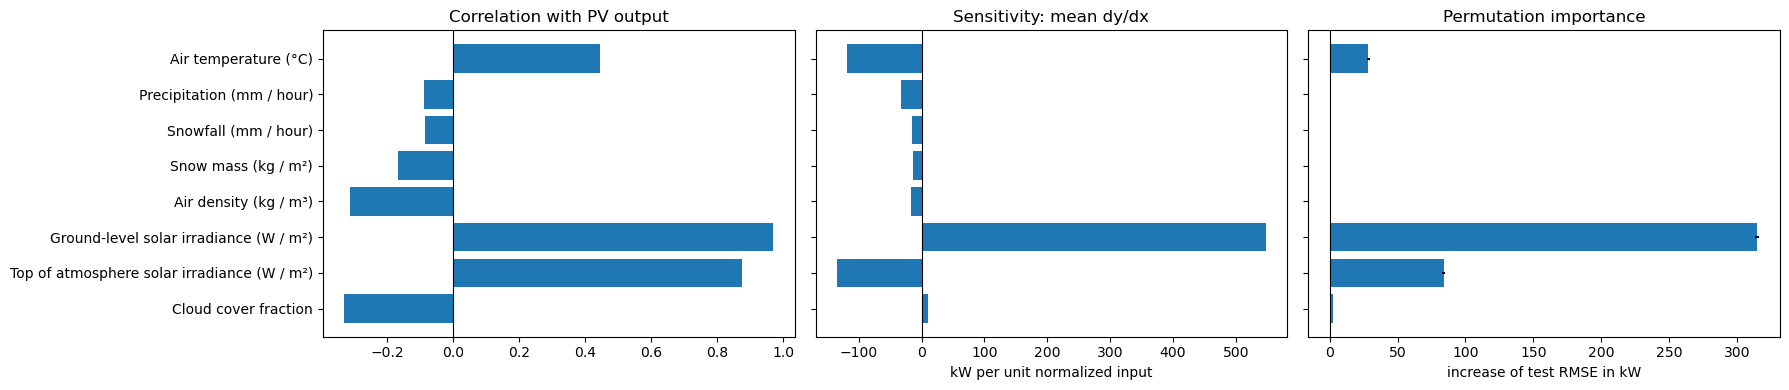

,model,feature,correlation_with_output,sensitivity_kW,abs_sensitivity_kW,permutation_RMSE_increase_kW,permutation_RMSE_increase_std
5,Deep NN,Ground-level solar irradiance (W / m²),0.970442,547.723370,547.723370,314.541276,1.221073
6,Deep NN,Top of atmosphere solar irradiance (W / m²),0.876627,-134.449124,134.449124,83.969972,1.054087
0,Deep NN,Air temperature (°C),0.445269,-117.925084,117.925084,28.557210,0.835329
7,Deep NN,Cloud cover fraction,-0.330192,10.773449,10.773449,2.335873,0.169477
4,Deep NN,Air density (kg / m³),-0.312663,-17.025060,17.025060,0.608578,0.130899
3,Deep NN,Snow mass (kg / m²),-0.167289,-13.120084,13.120084,0.025166,0.017556
1,Deep NN,Precipitation (mm / hour),-0.089098,-33.074802,33.074802,0.016682,0.007106
2,Deep NN,Snowfall (mm / hour),-0.084976,-15.922277,15.922277,0.000521,0.003884


In [ ]:
feature_names = data.columns[0:8]
final_parameters = deep_nn_model["parameters"]    
n_layers = len(final_parameters) // 2             

# readable feature names (used in the plot and in the results table)
label_map = {"t2m": "Air temperature (°C)",
             "prectotland": "Precipitation (mm / hour)",
             "precsnoland": "Snowfall (mm / hour)",
             "snomas": "Snow mass (kg / m²)",
             "rhoa": "Air density (kg / m³)",
             "swgdn": "Ground-level solar irradiance (W / m²)",
             "swtdn": "Top of atmosphere solar irradiance (W / m²)",
             "cldtot": "Cloud cover fraction"}
plot_labels = [label_map[f] for f in feature_names]

# 1. Correlation of every input with the output (training set only)
correlation = data.iloc[:split].corr()[data.columns[-1]][feature_names]

# 2. Sensitivity dy/dx instead of the weights: a deep NN has no single weight per input
#    (W1 is 8x8 and goes through 2 hidden layers), so the effect of each input is computed with the
#    chain rule through the layers (ReLU in the hidden layers, sigmoid at the output), for every hour of the test set
A = test_set_x_normalized
Z_list = []
for l in range(1, n_layers + 1):
    Z = final_parameters["W" + str(l)] @ A + final_parameters["b" + str(l)]
    Z_list.append(Z)
    A = np.maximum(0, Z) if l < n_layers else 1 / (1 + np.exp(-Z))
G = A * (1 - A)                                   # sigmoid'(z) at the output
for l in range(n_layers, 0, -1):
    G = final_parameters["W" + str(l)].T @ G
    if l > 1:
        G = G * (Z_list[l - 2] > 0)               # relu'(z) in the hidden layers
sensitivity = (G * scaler_y.data_range_[0]).mean(axis=1)    # mean dy/dx in kW per unit normalized input

# 3. Permutation importance: shuffle one feature of the test set and measure the increase of the RMSE in kW
n_repeats = 5
rng = np.random.default_rng(0)
base_rmse = test_scores["RMSE"]
perm_importance = np.zeros((len(feature_names), n_repeats))

for j in range(len(feature_names)):
    for r in range(n_repeats):
        x_shuffled = test_set_x_normalized.copy()
        x_shuffled[j, :] = rng.permutation(x_shuffled[j, :])
        y_shuffled, caches = L_model_forward(x_shuffled, final_parameters)    # Deep NN Prediction
        y_shuffled_kw = scaler_y.inverse_transform(y_shuffled.T)
        perm_importance[j, r] = evaluate(test_set_y_orig, y_shuffled_kw)["RMSE"] - base_rmse

feature_importance = pd.DataFrame({"model": model_name,
                                   "feature": plot_labels,
                                   "correlation_with_output": correlation.values,
                                   "sensitivity_kW": sensitivity,                  
                                   "abs_sensitivity_kW": np.abs(sensitivity),      
                                   "permutation_RMSE_increase_kW": perm_importance.mean(axis=1),
                                   "permutation_RMSE_increase_std": perm_importance.std(axis=1)})

fig, ax = plt.subplots(1, 3, figsize=(18, 4), sharey=True)

ax[0].barh(plot_labels, correlation.values)
ax[0].set_title('Correlation with PV output')
ax[1].barh(plot_labels, sensitivity)                              
ax[1].set_title('Sensitivity: mean dy/dx')                        
ax[1].set_xlabel('kW per unit normalized input')                  
ax[2].barh(plot_labels, perm_importance.mean(axis=1), xerr=perm_importance.std(axis=1))
ax[2].set_title('Permutation importance')
ax[2].set_xlabel('increase of test RMSE in kW')

ax[0].invert_yaxis()    # order of the features

for a in ax:
    a.axvline(0, color='black', linewidth=0.8)

plt.tight_layout()
plt.show()

feature_importance.sort_values("permutation_RMSE_increase_kW", ascending=False)

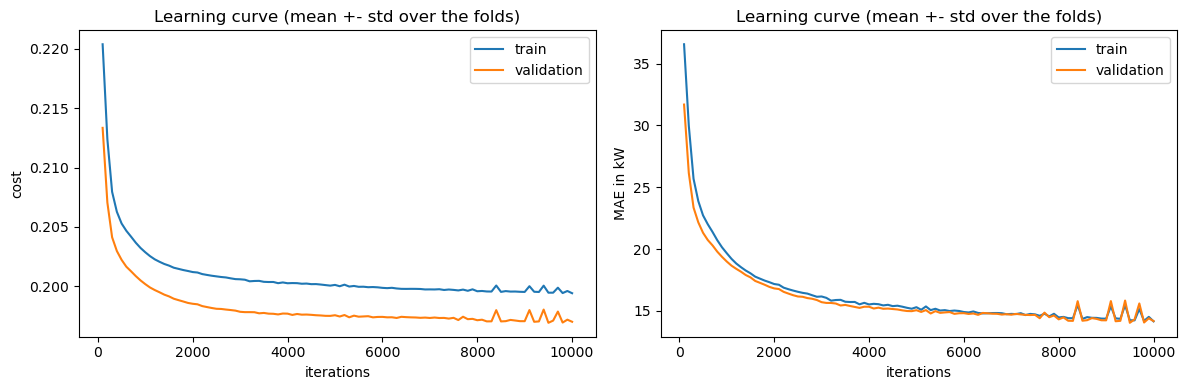

In [15]:

# Learning curves: train vs validation (mean over the CV folds)
total_iterations = 10000    # longer than the training above, to see if the validation error starts to rise
step = 100                 # evaluate every 100 iterations
n_points = total_iterations // step
 
train_cost = np.zeros((n_splits, n_points))
val_cost = np.zeros((n_splits, n_points))
train_mae = np.zeros((n_splits, n_points))
val_mae = np.zeros((n_splits, n_points))
 
for fold, (train_idx, val_idx) in enumerate(tscv.split(train_set_x_orig)):
    x_train = train_set_x_orig[train_idx]
    x_val = train_set_x_orig[val_idx]
    y_train = train_set_y_orig[train_idx]
    y_val = train_set_y_orig[val_idx]
 
    # same normalization as in the cross-validation
    scaler_x = MinMaxScaler(feature_range=(0,1))
    scaler_y = MinMaxScaler(feature_range=(0,1))
    x_train_normalized = scaler_x.fit_transform(x_train).T
    x_val_normalized = scaler_x.transform(x_val).T
    y_train_normalized = scaler_y.fit_transform(y_train).T
    y_val_normalized = scaler_y.transform(y_val).T
 
    y_range = np.max(y_train) - np.min(y_train)    # to convert the normalized error back to kW
 
    layers_dims = [x_train_normalized.shape[0]] + best_hidden_layers + [1]
    parameters = initialize_parameters_deep(layers_dims)
 
    for k in range(n_points):
        # continue the training for another 100 iterations (same steps as in L_layer_model)
        for i in range(step):
            AL, caches = L_model_forward(x_train_normalized, parameters)
            grads = L_model_backward(AL, y_train_normalized, caches)
            parameters = update_parameters(parameters, grads, best_learning_rate)
 
        AL_train, caches = L_model_forward(x_train_normalized, parameters)
        AL_val, caches = L_model_forward(x_val_normalized, parameters)
 
        train_cost[fold, k] = compute_cost(AL_train, y_train_normalized)
        val_cost[fold, k] = compute_cost(AL_val, y_val_normalized)
 
        train_mae[fold, k] = np.mean(np.abs(AL_train - y_train_normalized)) * y_range
        val_mae[fold, k] = np.mean(np.abs(AL_val - y_val_normalized)) * y_range
 
iterations = np.arange(step, total_iterations + 1, step)
 
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
 
for i, (train_curve, val_curve, label) in enumerate([(train_cost, val_cost, 'cost'), (train_mae, val_mae, 'MAE in kW')]):
    ax[i].plot(iterations, train_curve.mean(axis=0), label='train')
    # ax[i].fill_between(iterations, train_curve.mean(axis=0) - train_curve.std(axis=0), train_curve.mean(axis=0) + train_curve.std(axis=0), alpha=0.2)
    ax[i].plot(iterations, val_curve.mean(axis=0), label='validation')
    # ax[i].fill_between(iterations, val_curve.mean(axis=0) - val_curve.std(axis=0), val_curve.mean(axis=0) + val_curve.std(axis=0), alpha=0.2)
    ax[i].set_xlabel('iterations')
    ax[i].set_ylabel(label)
    ax[i].set_title('Learning curve (mean +- std over the folds)')
    ax[i].legend()
 
plt.tight_layout()
plt.show()

## Save the Results

Writes the CV table, the test results and the feature importance to `results/model_comparison.xlsx`, the same file as in the other notebooks. Only the rows of this model (column `model`) are replaced, so all models end up in the same tables and can be compared directly.

In [19]:
# Train and test periods (the notebooks do not all use the same split) and training time per iteration
test_results["train_period"] = "%s to %s" % (time[0], time[split - 1])
test_results["test_period"] = "%s to %s" % (time[split], time[-1])
test_results["time_per_iteration_ms"] = test_results["train_time_s"] / test_results["num_iterations"] * 1000

save_results({"cv": cv_results,
              "test": test_results,
              "feature_importance": feature_importance}, model_name)

print("results saved to", results_file)

results saved to results/model_comparison.xlsx
